In [1]:
import pandas as pd

data = pd.read_csv("../data/student_data.csv")

data.head()

,study_hours,attendance,previous_score,sleep_hours,internet_access,parental_support,extracurricular,result
0,5,85,72,7,Yes,High,Yes,Pass
1,2,60,45,6,Yes,Low,No,Fail
2,6,92,80,8,Yes,High,Yes,Pass
3,3,70,55,6,Yes,Medium,No,Pass
4,1,45,35,5,No,Low,No,Fail


In [3]:
data.shape

(15, 8)

In [4]:
data.dtypes


study_hours         int64
attendance          int64
previous_score      int64
sleep_hours         int64
internet_access       str
parental_support      str
extracurricular       str
result                str
dtype: object

In [5]:
data.isnull().sum()


study_hours         0
attendance          0
previous_score      0
sleep_hours         0
internet_access     0
parental_support    0
extracurricular     0
result              0
dtype: int64

In [6]:
data["result"].value_counts()

result
Pass    9
Fail    6
Name: count, dtype: int64

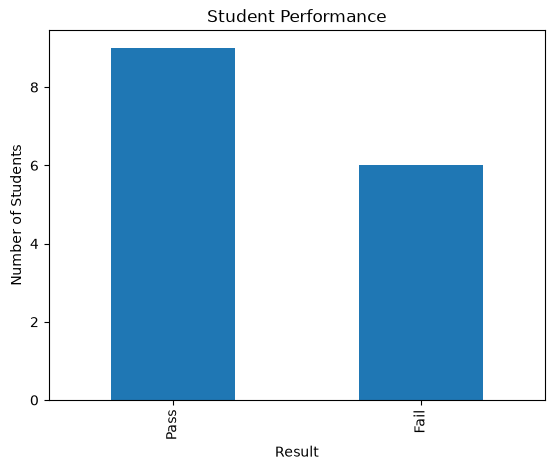

In [7]:
import matplotlib.pyplot as plt

data["result"].value_counts().plot(kind="bar")

plt.title("Student Performance")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.show()

In [8]:
data.groupby("result")["study_hours"].mean()


result
Fail    1.833333
Pass    5.333333
Name: study_hours, dtype: float64

In [9]:
data.groupby("result")["attendance"].mean()

result
Fail    55.500000
Pass    84.666667
Name: attendance, dtype: float64

In [10]:
data.groupby("result")["previous_score"].mean()


result
Fail    41.666667
Pass    73.333333
Name: previous_score, dtype: float64

In [11]:
data.groupby("result")["sleep_hours"].mean()

result
Fail    5.666667
Pass    7.222222
Name: sleep_hours, dtype: float64

In [12]:
X = data.drop("result", axis=1)
y = data["result"]

print("Features (X):")
print(X)

print("\nTarget (y):")
print(y)


Features (X):
    study_hours  attendance  previous_score  sleep_hours internet_access  \
0             5          85              72            7             Yes   
1             2          60              45            6             Yes   
2             6          92              80            8             Yes   
3             3          70              55            6             Yes   
4             1          45              35            5              No   
5             7          95              88            8             Yes   
6             4          78              65            7             Yes   
7             2          55              40            6              No   
8             5          82              70            7             Yes   
9             1          50              38            5              No   
10            8          97              92            8             Yes   
11            3          65              50            6             Yes  

In [13]:
X_encoded = pd.get_dummies(X, dtype=int)

print(X_encoded)

    study_hours  attendance  previous_score  sleep_hours  internet_access_No  \
0             5          85              72            7                   0   
1             2          60              45            6                   0   
2             6          92              80            8                   0   
3             3          70              55            6                   0   
4             1          45              35            5                   1   
5             7          95              88            8                   0   
6             4          78              65            7                   0   
7             2          55              40            6                   1   
8             5          82              70            7                   0   
9             1          50              38            5                   1   
10            8          97              92            8                   0   
11            3          65             

In [14]:
X_encoded.shape

(15, 11)

In [15]:
y_encoded = y.map({"Fail": 0, "Pass": 1})

print(y_encoded)

0     1
1     0
2     1
3     1
4     0
5     1
6     1
7     0
8     1
9     0
10    1
11    0
12    1
13    0
14    1
Name: result, dtype: int64


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (12, 11)
Testing data: (3, 11)


In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [18]:
model


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [19]:

y_pred = model.predict(X_test)

print(y_pred)


[0 1 1]


In [20]:
print(y_test.values)

[0 1 1]


In [21]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 1.0


In [22]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



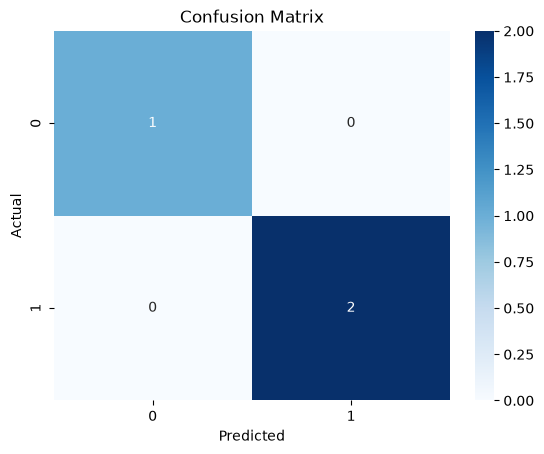

In [23]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [24]:
new_student = pd.DataFrame({
    "study_hours": [6],
    "attendance": [90],
    "previous_score": [78],
    "sleep_hours": [7],
    "internet_access": ["Yes"],
    "parental_support": ["High"],
    "extracurricular": ["Yes"]
})

new_student

,study_hours,attendance,previous_score,sleep_hours,internet_access,parental_support,extracurricular
0,6,90,78,7,Yes,High,Yes


In [25]:
new_student_encoded = pd.get_dummies(new_student, dtype=int)

new_student_encoded = new_student_encoded.reindex(
    columns=X_encoded.columns,
    fill_value=0
)

print(new_student_encoded)

   study_hours  attendance  previous_score  sleep_hours  internet_access_No  \
0            6          90              78            7                   0   

   internet_access_Yes  parental_support_High  parental_support_Low  \
0                    1                      1                     0   

   parental_support_Medium  extracurricular_No  extracurricular_Yes  
0                        0                   0                    1  


In [26]:
prediction = model.predict(new_student_encoded)

print("Prediction:", prediction)

Prediction: [1]


In [27]:
if prediction[0] == 1:
    print("Predicted Result: PASS")
else:
    print("Predicted Result: FAIL")

Predicted Result: PASS


In [28]:
import joblib

joblib.dump(model, "../models/student_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [29]:
joblib.dump(X_encoded.columns.tolist(), "../models/feature_columns.pkl")

print("Feature columns saved successfully!")

Feature columns saved successfully!


In [30]:
from src.data_preprocessing import load_data, preprocess_data

data = load_data()

X_encoded, y_encoded = preprocess_data(data)

print("Features shape:", X_encoded.shape)
print("Target shape:", y_encoded.shape)

ModuleNotFoundError: No module named 'src'

In [31]:
import sys
sys.path.append("..")

In [32]:
from src.data_preprocessing import load_data, preprocess_data

data = load_data()

X_encoded, y_encoded = preprocess_data(data)

print("Features shape:", X_encoded.shape)
print("Target shape:", y_encoded.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'data/student_data.csv'

In [33]:
from src.data_preprocessing import load_data, preprocess_data

data = load_data()

X_encoded, y_encoded = preprocess_data(data)

print("Features shape:", X_encoded.shape)
print("Target shape:", y_encoded.shape)


FileNotFoundError: [Errno 2] No such file or directory: 'data/student_data.csv'

In [1]:
from src.data_preprocessing import load_data, preprocess_data

data = load_data()

X_encoded, y_encoded = preprocess_data(data)

print("Features shape:", X_encoded.shape)
print("Target shape:", y_encoded.shape)

ModuleNotFoundError: No module named 'src'

In [2]:
import sys
sys.path.append("..")

In [3]:
from src.data_preprocessing import load_data, preprocess_data

data = load_data()

X_encoded, y_encoded = preprocess_data(data)

print("Features shape:", X_encoded.shape)
print("Target shape:", y_encoded.shape)

Features shape: (15, 11)
Target shape: (15,)
